## 1. Setup
### 1a. Import Libraries

In [1]:
# ==========================================
# Requirements & Environment Documentation
# ==========================================
# System Requirements:
# - Python 3.8+
# - MATLAB R2022a or newer 
# - MATLAB Toolboxes: 
#   * Statistics and Machine Learning Toolbox (for fitrgp)
#   * Predictive Maintenance Toolbox (for phaseSpaceReconstruction)
# 
# Python Package Dependencies:
# - matlabengine
# - numpy, pandas, scipy, scikit-learn
# - matplotlib, seaborn
# - pyEDM (Pinned version recommended for SMap compatibility)
# - joblib, tqdm, ipython
# ==========================================

import sys
import numpy as np
import pandas as pd
import matplotlib
import seaborn as sns
import scipy
import sklearn
import joblib
import pyEDM

print("Python version:", sys.version.split('|')[0].strip())
print(f"{'numpy:':<15} {np.__version__}")
print(f"{'pandas:':<15} {pd.__version__}")
print(f"{'matplotlib:':<15} {matplotlib.__version__}")
print(f"{'seaborn:':<15} {sns.__version__}")
print(f"{'scipy:':<15} {scipy.__version__}")
print(f"{'sklearn:':<15} {sklearn.__version__}")
print(f"{'joblib:':<15} {joblib.__version__}")
print(f"{'pyEDM:':<15} {pyEDM.__version__}")

# Set random seeds for total reproducibility
import random
seed = 42
random.seed(seed)
np.random.seed(seed)


Python version: 3.12.2
numpy:          2.4.6
pandas:         3.0.3
matplotlib:     3.11.0
seaborn:        0.13.2
scipy:          1.18.0
sklearn:        1.9.0
joblib:         1.5.3
pyEDM:          2.5.7


In [2]:
import os
import atexit
from pathlib import Path
import matlab.engine
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.stats import pearsonr
from joblib import Parallel, delayed, parallel_config
from tqdm import tqdm
import pyEDM


In [4]:
# Set up matlabengine for running MATLAB code

# Setup workspace directory for MATLAB files
MATLAB_DIR = Path('matlab_workspace').resolve()
MATLAB_DIR.mkdir(exist_ok=True)

_ENG = None

def get_matlab_engine():
    global _ENG
    if _ENG is not None:
        return _ENG
    
    eng = matlab.engine.start_matlab()
    eng.addpath(str(MATLAB_DIR), nargout=0)
    _ENG = eng
    return _ENG

def reset_matlab_engine():
    global _ENG
    if _ENG is not None:
        try:
            _ENG.quit()
        except Exception:
            pass
        finally:
            _ENG = None

# Register cleanup on Python exit
atexit.register(reset_matlab_engine)

# Initialize engine immediately on startup
eng = get_matlab_engine()


### 1b. Load Datasets

In [5]:
DATA_DIR = Path("Data").resolve()
try:
    # Synthetic datasets
    lorenz120D_df  = pd.read_csv(DATA_DIR / 'lorenz120D_w0.1.csv')
    rossler120D_df = pd.read_csv(DATA_DIR / 'rossler120D_w0.01.csv')

    # Real-world datasets
    road_df        = pd.read_excel(DATA_DIR / 'Transportation.xlsx', header=None).pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
    eeg_df         = pd.read_excel(DATA_DIR / 'EEG data.xlsx', header=None)[1:].pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
    exchange_df    = pd.read_excel(DATA_DIR / 'Exchange rates.xlsx', header=None)[2:].pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))
    wind_df        = pd.read_csv(DATA_DIR / 'Wind speed.csv').pipe(lambda df: df.set_axis([f'X{i}' for i in range(1, len(df.columns) + 1)], axis=1))

    # Preprocessing
    eeg_df      = (eeg_df - eeg_df.mean()) / eeg_df.std()
    exchange_df = (exchange_df - exchange_df.mean()) / exchange_df.std()
    exchange_df = exchange_df.reset_index(drop=True)
    exchange_df = exchange_df.astype(float)

    # S-map / MVCM settings
    DEFAULTS = dict(E_list=[1,5,9], tau_list=[-1,-5,-9], theta_list=[1.,5.,9.])

    SYSTEMS = {
        'lorenz120D':   dict(df=lorenz120D_df,  full='X1', E_reported=4, tau_reported=3, **DEFAULTS),
        'rossler120D':  dict(df=rossler120D_df, full='X1', E_reported=5, tau_reported=2, **DEFAULTS),
        'road':         dict(df=road_df,        full='X1', E_reported=6, tau_reported=4, **DEFAULTS),
        'eeg':          dict(df=eeg_df,         full='X1', E_reported=3, tau_reported=3, **DEFAULTS),
        'exchange':     dict(df=exchange_df,    full='X1', E_reported=4, tau_reported=4, **DEFAULTS),
        'wind':         dict(df=wind_df,        full='X1', E_reported=4, tau_reported=6, **DEFAULTS),
    }
except Exception as e:
    print(f"Data missing: {e}")


### 1c. Method Names and Colors

In [6]:
# Method names, labels and colours shared by the examples, tables and plots
METHOD_ORDER  = ('smap', 'mvcm', 'fprm')
METHOD_LABELS = {'smap': 'S-map', 'mvcm': 'MVCM', 'fprm': 'FPRM'}
METHOD_COLORS = dict(zip(METHOD_ORDER, ['tab:orange', 'tab:green', 'tab:red']))


## 2. Shared Functions

In [7]:
def smap_vec(Z, y, lib_i, pred_i, thetas, knn=None, Tp=0, exclusion_radius=0, valid_lib=None):
    lib_i = np.asarray(lib_i, int)
    pred_i = np.asarray(pred_i, int)

    # Identify rows in Z without any NaNs
    valid_rows = ~np.isnan(Z).any(axis=1)
    lib_ok = lib_i[valid_rows[lib_i]]
    pred_ok_mask = valid_rows[pred_i]
    pred_ok = pred_i[pred_ok_mask]

    lib_all_n = len(lib_i)

    if knn is None:
        knn = (len(lib_ok) - 1 if len(lib_ok) < lib_all_n else lib_all_n - 1)

    if valid_lib is not None:
        lib_ok = lib_ok[np.asarray(valid_lib)[lib_ok]]
        if len(lib_ok) < knn:
            raise ValueError('valid library smaller than knn')
        k_query = None
    else:
        has_overlap = np.isin(pred_ok, lib_ok).any()
        if exclusion_radius > 0:
            k_query = min(knn * 5, len(lib_ok))
        else:
            k_query = knn + 1 if has_overlap else knn

    D = cdist(Z[pred_ok], Z[lib_ok], metric='euclidean')

    res = smap_core(D, Z[lib_ok], Z[pred_ok], y[lib_ok + Tp], lib_ok, pred_ok, thetas, knn,
                    exclusion_radius, k_query)

    n_thetas = len(np.atleast_1d(thetas))
    out = np.full((n_thetas, len(pred_i)), np.nan)
    out[:, pred_ok_mask] = res
    return out

def smap_core(D, Zlib, Zpred, ylib, lib_i, pred_i, thetas, knn, exclusion_radius=0, k_query=None, chunk_elems=2e7):
    thetas = np.atleast_1d(np.asarray(thetas, float))
    P, L = D.shape     
    d = Zlib.shape[1]  
    K = d + 1          

    Dm = D.copy()
    if k_query is not None and k_query < L:
        kth = np.partition(D, k_query - 1, axis=1)[:, k_query - 1 : k_query]
        Dm[D > kth] = np.inf  

    temporal_dist = np.abs(pred_i[:, None] - lib_i[None, :])
    Dm[temporal_dist <= exclusion_radius] = np.inf

    sel = np.isfinite(Dm)
    drop = np.maximum(sel.sum(1) - knn, 0)
    if drop.max(initial=0) > 0:
        if drop.max() == 1:
            far = np.where(sel, Dm, -np.inf).argmax(1)
            r = np.where(drop > 0)[0]
            Dm[r, far[r]] = np.inf
        else:
            rank = np.argsort(np.argsort(Dm, axis=1, kind='stable'), axis=1, kind='stable')
            Dm[rank >= knn] = np.inf
        sel = np.isfinite(Dm)
        
    cnt = sel.sum(1)
    Dz = np.where(sel, Dm, 0.0)
    dmean = np.where(cnt > 0, Dz.sum(1) / np.maximum(cnt, 1), np.nan)

    yfin = np.isfinite(ylib)
    valid = sel & yfin[None, :]       
    rows = np.where(valid.any(1))[0]  
    M = valid.sum(1)                  

    Zaug = np.hstack([np.ones((L, 1)), Zlib])  
    yz = np.where(yfin, ylib, 0.0)

    step = max(1, int(chunk_elems // (L * K)))

    preds = np.full((len(thetas), P), np.nan)
    for t, theta in enumerate(thetas):
        for s0 in range(0, len(rows), step):
            r = rows[s0: s0 + step]
            
            if theta == 0:
                W = valid[r].astype(float)
            else:
                scale = (theta / dmean[r])[:, None]
                W = np.where(valid[r], np.exp(-scale * Dz[r]), 0.0)

            A = W[:, :, None] * Zaug[None, :, :]
            b = W * yz[None, :]

            C = _solve_svd(A, b, M[r])

            preds[t, r] = C[:, 0] + np.einsum('pk,pk->p', C[:, 1:], Zpred[r])
    return preds

_EPS = np.finfo(float).eps

def _solve_svd(A, b, M):
    K = A.shape[2]
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    cutoff = (_EPS * np.maximum(M, K))[:, None] * s[:, :1]
    sinv = np.where(s > cutoff, 1.0 / np.where(s > 0, s, 1.0), 0.0)
    Utb = np.einsum('plk,pl->pk', U, b)
    return np.einsum('pkj,pk->pj', Vt, sinv * Utb)


In [8]:
def make_observed(df, missing_frac, full, seed):
    rng = np.random.default_rng(seed)
    is_observed = pd.DataFrame(rng.random(size=df.shape) >= missing_frac, index=df.index, columns=df.columns)
    is_observed[full] = True
    return is_observed


In [9]:
def evaluate_view(df, block, columns, target, maskTrn, E, theta_list, exclusionRadius, mode, use_pyedm=False):
    maskTrn = np.asarray(maskTrn)
    pred_rows = np.where(maskTrn if mode == 'train' else ~maskTrn)[0]

    X = block.loc[:, columns].copy()
    Y = df[target].copy()
    
    if mode == 'train': 
        X.loc[~maskTrn, :] = np.nan
        Y.loc[~maskTrn] = np.nan

    mu, sigma = X[maskTrn].mean(), X[maskTrn].std(axis=0, ddof=0)
    Z = (X - mu) / np.where(sigma == 0, 1.0, sigma)

    n_lib = int((maskTrn & Z.notna().all(axis=1).to_numpy()).sum())
    if n_lib < 3:
        return []
    knn = n_lib - 1

    if use_pyedm:
        import importlib
        SMapClass = importlib.import_module('pyEDM.SMap').SMap
        df_edm = pd.concat([Z, Y], axis=1).reset_index(drop=True)
        smap_obj = SMapClass(
            dataFrame=df_edm, columns=list(Z.columns), target=target,
            lib=f'1 {len(df_edm)}', pred=f'1 {len(df_edm)}', validLib=maskTrn, knn=knn,
            Tp=0, theta=0, exclusionRadius=exclusionRadius if mode == 'train' else 0,
            embedded=True, noTime=True
        )
        smap_obj.EmbedData()
        smap_obj.RemoveNan()
        smap_obj.FindNeighbors()

        view_theta_sweep = []
        for theta in theta_list:
            smap_obj.theta = theta
            smap_obj.Project()
            smap_obj.FormatProjection()

            P = smap_obj.Projection
            row = P['Time'].to_numpy() - 1
            pred_df = (P.assign(row=row).loc[np.isin(row, pred_rows), ['row', 'Observations', 'Predictions']].dropna().set_index('row'))

            m = _metrics(pred_df['Observations'], pred_df['Predictions'])
            view_theta_sweep.append({'E': E, 'embedding': columns, 'theta': theta, 
                                     'rho': m['rho'], 'rmse': m['rmse'], 'nrmse': m['nrmse'],
                                     'preds': pred_df, 'n_preds': len(pred_df)})
            
    else:
        Z = Z.to_numpy(float)
        Y = Y.to_numpy(float)
        preds = smap_vec(Z, Y, lib_i = np.arange(len(X)), pred_i=pred_rows, thetas=theta_list, knn=knn,
                        exclusion_radius=exclusionRadius if mode == 'train' else 0, valid_lib=maskTrn)

        view_theta_sweep = []
        for t, theta in enumerate(theta_list):
            pred_df = pd.DataFrame({'Observations': Y[pred_rows], 'Predictions': preds[t]},
                                   index=pd.Index(pred_rows, name='row')).dropna()

            m = _metrics(pred_df['Observations'], pred_df['Predictions'])
            view_theta_sweep.append({'E': E, 'embedding': columns, 'theta': theta, 
                                     'rho': m['rho'], 'rmse': m['rmse'], 'nrmse': m['nrmse'],
                                     'preds': pred_df, 'n_preds': len(pred_df)})
    
    return view_theta_sweep


In [10]:
def _metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    if len(y) < 3 or np.std(p) == 0:
        return dict(rho=np.nan, rmse=np.nan, nrmse=np.nan)
    rmse = float(np.sqrt(np.mean((y - p) ** 2)))
    return dict(rho=float(np.corrcoef(y, p)[0, 1]), rmse=rmse, nrmse=rmse / float(np.std(y)))


## 3. S-Map Imputation

In [11]:
def smap_impute(df, missing_frac, full, partial, E_list, tau_list, theta_list, exclusionRadius, 
                showPlot=False, seed=None, use_pyedm=False):

    is_observed = make_observed(df, missing_frac, full, seed)
    maskTrn = is_observed[partial].to_numpy()

    records = []
    for E in E_list:
        for tau in tau_list:
            block = pyEDM.Embed(dataFrame=df, columns=full, E=E, tau=tau)
            theta_sweep = evaluate_view(
                df=df, block=block, columns=list(block.columns), target=partial,
                maskTrn=maskTrn, E=E, theta_list=theta_list,
                exclusionRadius=exclusionRadius, mode='train', use_pyedm=use_pyedm
            )
            for item in theta_sweep:
                records.append({'E': E, 'tau': tau, 'theta': item['theta'], 'rho': item['rho'], 'nrmse': item['nrmse']})
                
    parameter_grid = pd.DataFrame(records).sort_values(by='rho', ascending=False).reset_index(drop=True)
    best = parameter_grid.iloc[0]
    best_E, best_tau, best_theta = int(best['E']), int(best['tau']), float(best['theta'])

    best_block = pyEDM.Embed(dataFrame=df, columns=full, E=best_E, tau=best_tau)
    final_prediction = evaluate_view(
        df=df, block=best_block, columns=list(best_block.columns), target=partial,
        maskTrn=maskTrn, E=best_E, theta_list=[best_theta],
        exclusionRadius=exclusionRadius, mode='test', use_pyedm=use_pyedm
    )
    pred_df = final_prediction[0]['preds']

    original_series = df[partial].values
    imputed_series = np.full(len(df), np.nan)
    imputed_series[pred_df.index] = pred_df['Predictions'].values

    result_df = pd.DataFrame({
        f'{partial}_complete': original_series,
        f'{partial}_observed': np.where(maskTrn, original_series, np.nan),
        f'{partial}_imputed': imputed_series
    }, index=df.index)

    eval_df = result_df[[f'{partial}_complete', f'{partial}_imputed']].dropna()
    true_vals, imputed_vals = eval_df[f'{partial}_complete'].values, eval_df[f'{partial}_imputed'].values
    m = _metrics(true_vals, imputed_vals)
    rho, nrmse = m['rho'], m['nrmse']

    if showPlot:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(12, 4))
        result_df.plot(y=f'{partial}_complete', ax=ax, alpha=0.5, c='gray')
        result_df.plot(y=f'{partial}_imputed', ax=ax, marker='.', markersize=3, ls='None', c=METHOD_COLORS['smap'])
        ax.set_title(f'{partial} S-Map Imputation (E={best_E}, tau={best_tau}, theta={best_theta})\nρ={rho:.3f}, nRMSE={nrmse:.3f} (N={len(eval_df)})')
        plt.show()

    return {
        'params': {'E': best_E, 'tau': best_tau, 'theta': best_theta},
        'metrics': {'rho': rho, 'nrmse': nrmse, 'N': len(imputed_vals)},
        'train_rho': float(best['rho']),
        'train_nrmse': float(best['nrmse']),
        'parameter_grid': parameter_grid,
        'result_df': result_df
    }


## 4. MVCM Imputation
### 4a. Helper Functions

In [12]:
def get_embedding_list(maskTrn, maskTest, block, E, rng, min_candidates_per_gap, min_train_overlap,
                       max_combos_per_row_pass=3, exhaustive=False, max_embeddings=1e6, verbose=True):
    import math
    col_names = np.array(block.columns)
    is_observed = ~block.isna().to_numpy()

    train_rows = np.where(maskTrn)[0]
    test_rows = np.where(maskTest)[0]

    n_train_per_col = is_observed[train_rows].sum(axis=0)
    eligible_cols = np.where(n_train_per_col >= min_train_overlap)[0]

    if len(eligible_cols) < E:
        if verbose:
            print(f'Not enough eligible columns to create embeddings for E={E}.')
        return None, {'skipped': f'fewer than E={E} eligible columns', 'n_eligible_cols': int(len(eligible_cols))}

    obs_train = is_observed[train_rows][:, eligible_cols]
    obs_test = is_observed[test_rows][:, eligible_cols]

    fillable_trn_mask = obs_train.sum(axis=1) >= E
    fillable_test_mask = obs_test.sum(axis=1) >= E

    obs_fillable_trn = obs_train[fillable_trn_mask]
    obs_fillable_test = obs_test[fillable_test_mask]

    pair_overlap = obs_train.astype(int).T @ obs_train.astype(int)
    valid_pair_adj = pair_overlap >= min_train_overlap

    def passes_criterion_1(combo):
        for i in range(E):
            for j in range(i+1, E):
                if not valid_pair_adj[combo[i], combo[j]]:
                    return False
        joint_overlap = (obs_train[:, list(combo)].sum(axis=1) == E).sum()
        return joint_overlap >= min_train_overlap

    def compatible_combos(candidates, E):
        def extend(combo, available_indices):
            if len(combo) == E:
                yield tuple(sorted(combo))
                return
            for i, idx in enumerate(available_indices):
                c = candidates[idx]
                if all(valid_pair_adj[c, x] for x in combo):
                    new_available = available_indices[i + 1:]
                    yield from extend(combo + (c,), new_available)
        yield from extend((), np.arange(len(candidates)))

    M_eligible = len(eligible_cols)
    total_raw_combos = math.comb(M_eligible, E)
    if exhaustive:
        if total_raw_combos > max_embeddings and verbose:
            print(f'WARNING: Exhaustive search space for E={E} has {total_raw_combos} raw combinations.')

        valid_combos = []
        def build_combos(current_combo, start_idx):
            if len(current_combo) == E:
                valid_combos.append(current_combo)
                return
            for i in range(start_idx, M_eligible):
                if all(valid_pair_adj[i, c] for c in current_combo):
                    build_combos(current_combo + (i,), i + 1)
        build_combos((), 0)

        selected_combos = []
        for combo in valid_combos:
            joint_overlap = (obs_train[:, list(combo)].sum(axis=1) == E).sum()
            if joint_overlap >= min_train_overlap:
                selected_combos.append(combo)
        embeddings = [tuple(col_names[eligible_cols[list(c)]]) for c in selected_combos]

        if len(selected_combos) > 0:
            combo_matrix = np.array(selected_combos)
            views_per_test_row = np.zeros(len(obs_fillable_test), dtype=int)
            views_per_trn_row = np.zeros(len(obs_fillable_trn), dtype=int)
            
            for combo in selected_combos:
                views_per_test_row += (obs_fillable_test[:, list(combo)].sum(axis=1) == E)
                views_per_trn_row += (obs_fillable_trn[:, list(combo)].sum(axis=1) == E)
        else:
            views_per_test_row = np.zeros(len(obs_fillable_test), dtype=int)
            views_per_trn_row = np.zeros(len(obs_fillable_trn), dtype=int)
            
        diagnostics = {
            "n_embeddings": len(embeddings),
            "n_trn_total": len(train_rows),
            "n_test_total": len(test_rows),
            "n_trn_fillable": int(fillable_trn_mask.sum()),
            "n_test_fillable": int(fillable_test_mask.sum()),
            "unfillable_trn_rows": train_rows[~fillable_trn_mask].tolist(),
            "unfillable_test_rows": test_rows[~fillable_test_mask].tolist(),
            "undercovered_test_rows": dict(zip(test_rows[fillable_test_mask][views_per_test_row < min_candidates_per_gap].tolist(),
                                               views_per_test_row[views_per_test_row < min_candidates_per_gap].tolist(),)),
            "undercovered_trn_rows": dict(zip(train_rows[fillable_trn_mask][views_per_trn_row < min_candidates_per_gap].tolist(),
                                              views_per_trn_row[views_per_trn_row < min_candidates_per_gap].tolist(),)),}
        diagnostics['n_eligible_cols'] = int(len(eligible_cols))
        if verbose:
            print_diagnostic_warnings(diagnostics, min_candidates_per_gap)
        return embeddings, diagnostics
        
    selected_combos = set()
    views_per_test_row = np.zeros(len(obs_fillable_test), dtype=int)
    views_per_trn_row = np.zeros(len(obs_fillable_trn), dtype=int)

    all_target_obs = np.vstack([obs_fillable_test, obs_fillable_trn])
    is_test_flag = np.array([True] * len(obs_fillable_test) + [False] * len(obs_fillable_trn))

    while True:
        test_needy = views_per_test_row < min_candidates_per_gap
        trn_needy = views_per_trn_row < min_candidates_per_gap
        needy_mask = np.concatenate([test_needy, trn_needy])
        needy_indices = np.where(needy_mask)[0]

        if len(needy_indices) == 0:
            break

        needy_indices = rng.permutation(needy_indices)
        added_in_this_pass = 0

        for row_idx in needy_indices:
            if is_test_flag[row_idx]:
                if views_per_test_row[row_idx] >= min_candidates_per_gap:
                    continue
            else:
                trn_idx = row_idx - len(obs_fillable_test)
                if views_per_trn_row[trn_idx] >= min_candidates_per_gap:
                    continue

            row_obs_cols = np.where(all_target_obs[row_idx] == 1)[0]
            if len(row_obs_cols) < E:
                continue

            shuffled_cols = rng.permutation(row_obs_cols)
            row_added = 0

            for combo in compatible_combos(shuffled_cols, E):
                sorted_combo = tuple(sorted(combo))

                if sorted_combo in selected_combos:
                    continue
                if not passes_criterion_1(sorted_combo):
                    continue

                selected_combos.add(sorted_combo)
                added_in_this_pass += 1
                row_added += 1

                covers_test = obs_fillable_test[:, list(sorted_combo)].sum(axis=1) == E
                covers_trn = obs_fillable_trn[:, list(sorted_combo)].sum(axis=1) == E
    
                views_per_test_row += covers_test.astype(int)
                views_per_trn_row += covers_trn.astype(int)

                if row_added >= max_combos_per_row_pass:
                    break
                if len(selected_combos) >= max_embeddings:
                    break

            if len(selected_combos) >= max_embeddings:
                break

        if added_in_this_pass == 0 or len(selected_combos) >= max_embeddings:
            break

    selected_list = list(selected_combos)
    embeddings = [tuple(col_names[eligible_cols[list(c)]]) for c in selected_list]

    test_undercovered_mask = views_per_test_row < min_candidates_per_gap
    trn_undercovered_mask = views_per_trn_row < min_candidates_per_gap
    
    undercovered_test_indices = test_rows[fillable_test_mask][test_undercovered_mask].tolist()
    undercovered_trn_indices = train_rows[fillable_trn_mask][trn_undercovered_mask].tolist()
    
    test_counts = views_per_test_row[test_undercovered_mask].tolist()
    trn_counts = views_per_trn_row[trn_undercovered_mask].tolist()

    diagnostics = {
        'n_embeddings': len(embeddings),
        'n_trn_total': len(train_rows),
        'n_test_total': len(test_rows),
        'n_trn_fillable': int(fillable_trn_mask.sum()),
        'n_test_fillable': int(fillable_test_mask.sum()),
        'unfillable_trn_rows': train_rows[~fillable_trn_mask].tolist(),
        'unfillable_test_rows': test_rows[~fillable_test_mask].tolist(),
        'undercovered_test_rows': dict(zip(undercovered_test_indices, test_counts)),
        'undercovered_trn_rows': dict(zip(undercovered_trn_indices, trn_counts)),
    }
    diagnostics['n_eligible_cols'] = int(len(eligible_cols))
    if verbose:
        print_diagnostic_warnings(diagnostics, min_candidates_per_gap)

    return embeddings, diagnostics

def print_diagnostic_warnings(diagnostics, min_candidates_per_gap):
    unfill_trn = diagnostics['unfillable_trn_rows']
    unfill_test = diagnostics['unfillable_test_rows']
    under_trn = diagnostics['undercovered_trn_rows']
    under_test = diagnostics['undercovered_test_rows']
    
    if len(unfill_trn) > 0 or len(unfill_test) > 0:
        n_trn_total = diagnostics.get('n_trn_total', len(unfill_trn) + len(under_trn))  
        n_test_total = diagnostics.get('n_test_total', len(unfill_test) + len(under_test))
        
        pct_unfill_trn = (len(unfill_trn) / n_trn_total * 100) if n_trn_total else 0
        pct_unfill_test = (len(unfill_test) / n_test_total * 100) if n_test_total else 0
        
        print(f"WARNING: Some indices are unfillable (< E observed columns). Try increasing numLags or lagTau.")
        print(f"  Train: {len(unfill_trn):>4}/{n_trn_total:<4} rows ({pct_unfill_trn:>5.1f}% unfillable)")
        print(f"  Test : {len(unfill_test):>4}/{n_test_total:<4} rows ({pct_unfill_test:>5.1f}% unfillable)")
    
    if under_trn or under_test:
        n_trn_fillable = diagnostics.get('n_trn_fillable', len(under_trn))
        n_test_fillable = diagnostics.get('n_test_fillable', len(under_test))
        
        pct_under_trn = (len(under_trn) / n_trn_fillable * 100) if n_trn_fillable else 0
        pct_under_test = (len(under_test) / n_test_fillable * 100) if n_test_fillable else 0
        
        min_v_trn = min(under_trn.values(), default=0)
        min_v_test = min(under_test.values(), default=0)
        
        print(f"WARNING: Some fillable indices have < {min_candidates_per_gap} candidate views. Try increasing numLags or lagTau.")
        print(f"  Train: {len(under_trn):>4}/{n_trn_fillable:<4} rows ({pct_under_trn:>5.1f}% undercovered) | min coverage = {min_v_trn:>3} views")
        print(f"  Test : {len(under_test):>4}/{n_test_fillable:<4} rows ({pct_under_test:>5.1f}% undercovered) | min coverage = {min_v_test:>3} views")


In [13]:
def build_embedding_block(observed_df, partial, use_self_lags=False, lags=None):
    """
    Construct embedding block using explicit lag offsets (`lags`).
    Parameters:
    - lags: list or array of ints, e.g., [-3, -2, -1, 0, 1, 2, 3].
            Negative values indicate past lags (t-tau), positive values indicate future lags (t+tau).
    """
    assert all(isinstance(lag, int) for lag in lags), "Lags must be integers"

    lags = sorted(list(set(lags)))
    block_cols = {}
    for col in observed_df.columns:
        for lag in lags:
            if lag == 0:
                lag_str = "(t-0)"
            elif lag > 0:
                lag_str = f"(t+{lag})"
            else:
                lag_str = f"(t{lag})"
            
            col_name = f"{col}{lag_str}"
            block_cols[col_name] = observed_df[col].shift(-lag)
    
    block = pd.DataFrame(block_cols, index=observed_df.index)

    if use_self_lags:
        cols_to_drop = [
            col for col in block.columns 
            if col.startswith(f"{partial}(") and ("(t-0)" in col or "(t+0)" in col)
        ]
    else:
        cols_to_drop = [
            col for col in block.columns 
            if col == partial or col.startswith(f"{partial}(")
        ]
        
    block = block.drop(columns=cols_to_drop, errors='ignore')
    return block


In [14]:
def colwise_rho(pred_matrix, observed, min_n=25):
    observed_col = observed[:, None]
    both_present = ~np.isnan(pred_matrix) & ~np.isnan(observed_col)
    n_overlap = both_present.sum(axis=0)

    with np.errstate(invalid='ignore', divide='ignore'):
        pred_mean = np.where(both_present, pred_matrix, 0.0).sum(axis=0) / n_overlap
        obs_mean = np.where(both_present, observed_col, 0.0).sum(axis=0) / n_overlap

        pred_dev = np.where(both_present, pred_matrix - pred_mean, 0.0)
        obs_dev = np.where(both_present, observed_col - obs_mean, 0.0)

        numerator = (pred_dev * obs_dev).sum(axis=0)
        denominator = np.sqrt((pred_dev ** 2).sum(axis=0) * (obs_dev ** 2).sum(axis=0))
        view_rhos = numerator / denominator

    view_rhos[(n_overlap < min_n) | ~np.isfinite(view_rhos)] = 0.0
    return view_rhos

def fold_rhos(pred_matrix, obs, n_folds, min_n):
    n = len(obs)
    min_n_fold = max(5, int(min_n * (n_folds - 1) / n_folds))
    folds = np.array_split(np.arange(n), n_folds)
    rhos = []
    for f in folds:
        keep = np.ones(n, bool); keep[f] = False
        rhos.append(np.clip(colwise_rho(pred_matrix[keep], obs[keep], min_n=min_n_fold), 0, None))
    return folds, np.vstack(rhos)

def view_feature_mask(candidate_views, block):
    col_map = {c: i for i, c in enumerate(block.columns)}
    m = np.zeros((len(candidate_views), block.shape[1]), dtype=bool)
    for v, combo in enumerate(candidate_views['embedding']):
        m[v, [col_map[c] for c in combo]] = True
    return m

def mvcm_compute(pred_matrix, candidate_views, target_mask, block, k):
    n_rows, n_views = pred_matrix.shape
    rho_weights = candidate_views['rho'].clip(lower=0).to_numpy()

    vfm = view_feature_mask(candidate_views, block)
    missing_feature_matrix = block.isna().to_numpy()[target_mask]
    valid_mask = ((missing_feature_matrix @ vfm.T) == 0) & ~np.isnan(pred_matrix)

    masked_preds = np.where(valid_mask, pred_matrix, np.nan)
    masked_rhos = np.where(valid_mask, rho_weights[None, :], -np.inf)
    sorted_indices = np.argsort(-masked_rhos, axis=1, kind='stable')
    top_k_indices = sorted_indices[:, :min(k, n_views)]

    row_indices = np.arange(n_rows)[:, None]
    top_k_preds = masked_preds[row_indices, top_k_indices]
    top_k_rhos = masked_rhos[row_indices, top_k_indices]

    valid_top_k = top_k_rhos > -np.inf
    top_k_rhos_clean = np.where(valid_top_k, np.maximum(top_k_rhos, 0), 0.0)

    sum_rhos = np.sum(top_k_rhos_clean, axis=1, keepdims=True)
    valid_counts = np.sum(valid_top_k, axis=1, keepdims=True)

    uniform_weights = np.where(valid_counts > 0, 1.0 / np.maximum(valid_counts, 1), 0.0)
    normalized_weights = np.where(sum_rhos > 0, top_k_rhos_clean / np.maximum(sum_rhos, 1e-12), uniform_weights * valid_top_k)

    top_k_preds_clean = np.nan_to_num(top_k_preds, nan=0.0)
    final_preds = np.sum(top_k_preds_clean * normalized_weights, axis=1)

    has_valid_views = valid_counts.squeeze(-1) > 0
    return np.where(has_valid_views, final_preds, np.nan)

def _union_topk(rho_folds, vfm, missing_test, k, chunk=256):
    V = vfm.shape[0]
    orders = [np.argsort(-np.clip(r, 0, None), kind='stable') for r in rho_folds]
    vfm_T = vfm.T.astype(np.float32)
    union = np.zeros(V, dtype=bool)
    for s in range(0, missing_test.shape[0], chunk):
        valid = (missing_test[s:s + chunk].astype(np.float32) @ vfm_T) == 0
        for order in orders:
            vs = valid[:, order]
            sel = vs & (vs.cumsum(axis=1) <= k)
            union[order[np.where(sel)[1]]] = True
    return np.where(union)[0]

def crossfit_all_k(pred_matrix, folds, rho_folds, vfm, missing_train, k_list, chunk=128):
    n, V = pred_matrix.shape
    P = pred_matrix.astype(np.float32, copy=False)
    fin = np.isfinite(P)
    vfm_T = vfm.T.astype(np.float32)
    miss = missing_train.astype(np.float32)
    out = {k: np.full(n, np.nan) for k in k_list}
    for f, rho in zip(folds, rho_folds):
        order = np.argsort(-rho, kind='stable')
        w_ord = rho[order].astype(np.float32)
        for s in range(0, len(f), chunk):
            rows = f[s:s + chunk]
            valid = ((miss[rows] @ vfm_T) == 0) & fin[rows]
            vs = valid[:, order]
            cs = vs.cumsum(1, dtype=np.int32)
            Pv = np.where(vs, P[rows][:, order], 0.0)
            for k in k_list:
                sel = vs & (cs <= k)
                w = sel * w_ord
                sw, nv = w.sum(1), sel.sum(1)
                pred = np.where(sw > 0, (Pv * w).sum(1) / np.maximum(sw, 1e-12),
                                (Pv * sel).sum(1) / np.maximum(nv, 1))
                out[k][rows] = np.where(nv > 0, pred, np.nan)
    return out

def predict_views_on_test(df, block, partial, cv_U, maskTrn, maskTest, E, theta, n_jobs=1, show_progress=False):
    test_rows = np.where(maskTest)[0]
    out = Parallel(n_jobs=n_jobs)(
        delayed(evaluate_view)(df=df, block=block, columns=emb, target=partial, maskTrn=maskTrn,
                               E=E, theta_list=[theta], exclusionRadius=0, mode='test')
        for emb in tqdm(cv_U['embedding'], total=len(cv_U), desc='Test views', disable=not show_progress))
    assert all(len(o) == 1 for o in out), 'evaluate_view returned no result for some views'
    return np.column_stack([o[0]['preds']['Predictions'].reindex(test_rows).to_numpy() for o in out])

def mvcm_final(df, block, partial, candidate_views, maskTrn, maskTest, best_E, best_theta, best_k,
               n_jobs_eff=1, show_progress=False):
    rho = candidate_views['rho'].fillna(0).clip(lower=0).to_numpy()
    vfm = view_feature_mask(candidate_views, block)
    U = _union_topk([rho], vfm, block.isna().to_numpy()[maskTest], best_k)
    if len(U) == 0:
        return np.full(int(maskTest.sum()), np.nan), 0
    cv_U = candidate_views.iloc[U].reset_index(drop=True)
    P = predict_views_on_test(df, block, partial, cv_U, maskTrn, maskTest, best_E, best_theta,
                              n_jobs_eff, show_progress)
    return mvcm_compute(P, cv_U, maskTest, block, best_k), len(cv_U)


### 4b. MVCM Pipeline

In [15]:
def train_views(df, block, embeddings, partial, maskTrn, E, theta_list, exclusionRadius,
                use_pyedm=False, n_jobs=1, show_progress=False):
    train_rows = np.where(maskTrn)[0]
    n_train = len(train_rows)
    pos = np.full(len(df), -1, dtype=np.int64)
    pos[train_rows] = np.arange(n_train)

    results = Parallel(n_jobs=n_jobs)(
        delayed(_train_one_view)(df, block, emb, partial, maskTrn, E, theta_list, exclusionRadius, pos, n_train, use_pyedm)
        for emb in tqdm(embeddings, desc=f'E={E} training views', disable=not show_progress))

    by_theta = {float(th): [] for th in theta_list}
    for emb, per_theta in results:
        for th, (rho, nrmse, vec) in per_theta.items():
            by_theta[th].append((emb, rho, nrmse, vec))
    
    views = {}
    for theta in theta_list:
        items = by_theta[float(theta)]
        if not items:
            continue
        rho = np.array([it[1] for it in items])
        nrmse = np.array([it[2] for it in items])
        order = np.argsort(-np.nan_to_num(rho, nan=-np.inf), kind='stable')
        cv = pd.DataFrame({'embedding': [items[i][0] for i in order], 
                           'E': E, 
                           'theta': float(theta),
                           'rho': np.nan_to_num(rho[order], nan=0.0),
                           'nrmse': np.nan_to_num(nrmse[order], nan=0.0),
                          })
        PM = np.column_stack([items[i][3] for i in order])
        views[float(theta)] = (cv, PM)

    return views

def _train_one_view(df, block, embedding, partial, maskTrn, E, theta_list, exclusionRadius, pos, n_train, use_pyedm):
    out = {}
    sweep = evaluate_view(df=df, block=block, columns=embedding, target=partial, maskTrn=maskTrn,
                          E=E, theta_list=theta_list, exclusionRadius=exclusionRadius, mode='train', use_pyedm=use_pyedm)
    for r in sweep:
        p = r['preds']['Predictions']
        idx = pos[p.index.to_numpy()]
        ok = idx >= 0
        vec = np.full(n_train, np.nan, dtype=np.float32)
        vec[idx[ok]] = p.to_numpy()[ok]

        rho = np.nan if r['rho'] is None else float(r['rho'])
        nrmse = np.nan if r['nrmse'] is None else float(r['nrmse'])
        
        out[float(r['theta'])] = (rho, nrmse, vec)
    return embedding, out

def score_k_values(cv, PM, block, obs_train, missing_train, k_list, n_folds, min_train_overlap):
    folds, rho_folds = fold_rhos(PM, obs_train, n_folds, min_train_overlap)
    vfm = view_feature_mask(cv, block)
    preds_by_k = crossfit_all_k(PM, folds, rho_folds, vfm, missing_train, k_list)
    scores = {}
    for k in k_list:
        mp = preds_by_k[k]
        ok = np.isfinite(mp) & np.isfinite(obs_train)
        if ok.sum() > 2 and np.std(mp[ok]) > 0 and np.std(obs_train[ok]) > 0:
            rho = float(np.corrcoef(obs_train[ok], mp[ok])[0, 1])
            nrmse = float(np.sqrt(np.mean((mp[ok] - obs_train[ok]) ** 2)) / np.std(obs_train[ok]))
        else:
            rho, nrmse = -np.inf, np.inf
        scores[k] = dict(cv_rho=rho, cv_nrmse=nrmse, n_preds=int(ok.sum()))
    return scores

def mvcm_impute(df, missing_frac, full, partial, E_list, theta_list, k_list, exclusionRadius,
                lags=None, tau_list=None, use_self_lags=False, min_candidates_per_gap=0, min_train_overlap=10,
                exhaustive=False, seed=None, parallel=False, n_jobs=-1,
                use_pyedm=False, n_folds=5, show_warnings=True, show_progress=False, showPlot=False):
    import time
    t_start = time.perf_counter()
    rng = np.random.default_rng(seed)
    n_jobs_eff = n_jobs if parallel else 1
    k_list = sorted(list(k_list))

    classic_taus = list(tau_list) if tau_list is not None else [1]

    is_observed = make_observed(df, missing_frac, full, seed)
    maskTrn = is_observed[partial].to_numpy()
    maskTest = ~maskTrn
    y_all = df[partial].to_numpy(float)
    obs_train = y_all[maskTrn]

    block = build_embedding_block(df.where(is_observed), partial, use_self_lags, lags)
    missing_train = block.isna().to_numpy()[maskTrn]

    best_score, best_cfg, best_store = -np.inf, None, None
    grid, n_pool, n_cand, emb_diag, skipped_E = [], {}, {}, {}, []
    
    for E in E_list:
        pool, emb_diag[E] = get_embedding_list(maskTrn, maskTest, block, E, rng, min_candidates_per_gap=min_candidates_per_gap,
                                               min_train_overlap=min_train_overlap, exhaustive=exhaustive, verbose=show_warnings)
        
        pool = add_classic_smap_embeddings(pool, block, full, E, classic_taus)
        
        if not pool:
            skipped_E.append(E)
            continue
        n_pool[E] = len(pool)
        n_cand[E] = len(pool)

        views = train_views(df, block, pool, partial, maskTrn, E, theta_list, exclusionRadius,
                            use_pyedm=use_pyedm, n_jobs=n_jobs_eff, show_progress=show_progress)
        
        for theta, (cv, PM) in views.items():
            scores = score_k_values(cv, PM, block, obs_train, missing_train, k_list, n_folds, min_train_overlap)
            for k, s in scores.items():
                grid.append(dict(E=E, theta=theta, k=k, **s))
                if s['cv_rho'] > best_score:
                    best_score, best_cfg, best_store = s['cv_rho'], (E, theta, k), (cv, PM)
            
    t_tune = time.perf_counter() - t_start
    grid_df = pd.DataFrame(grid)
    parameter_grid = grid_df.sort_values(by=['cv_rho'], ascending=False).reset_index(drop=True)

    if best_cfg is None:
        raise ValueError('No usable (E, theta, k)')

    bE, btheta, bk = best_cfg
    cv, PM = best_store
    final, n_eval = mvcm_final(df, block, partial, cv, maskTrn, maskTest, bE, btheta, bk,
                               n_jobs_eff=n_jobs_eff, show_progress=False)
    imputed = np.full(len(df), np.nan)
    imputed[maskTest] = final

    result_df = pd.DataFrame({f'{partial}_complete': y_all,
                              f'{partial}_observed': np.where(maskTrn, y_all, np.nan),
                              f'{partial}_imputed': imputed}, index=df.index)

    coverage = float(np.isfinite(final).mean())
    result_df.attrs.update(coverage=coverage, n_views_used=n_eval)

    eval_df = result_df[[f'{partial}_complete', f'{partial}_imputed']].dropna()
    true_vals, imputed_vals = eval_df[f'{partial}_complete'].to_numpy(), eval_df[f'{partial}_imputed'].to_numpy()
    m = _metrics(true_vals, imputed_vals)
    rho, nrmse = m['rho'], m['nrmse']

    if showPlot:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(12, 4))
        result_df.plot(y=f'{partial}_complete', ax=ax, alpha=0.5, c='gray')
        result_df.plot(y=f'{partial}_imputed', ax=ax, marker='.', markersize=3, linestyle='None', c=METHOD_COLORS['mvcm'])
        ax.set_title(f"{partial} MVCM Imputation (E={bE}, theta={btheta}, k={bk}): \n"
                     f"ρ={rho:.3f}, nRMSE={nrmse:.3f} (N={len(eval_df)})")
        plt.show()

    best_row = grid_df[(grid_df.E == bE) & (grid_df.theta == btheta) & (grid_df.k == bk)].iloc[0]
    d = emb_diag[bE]
    diagnostics = dict(
        best_cv_rho=float(best_row['cv_rho']), best_cv_nrmse=float(best_row['cv_nrmse']),
        n_pool=n_pool, n_cand=n_cand, n_views_used=n_eval, skipped_E=skipped_E,
        n_test=int(maskTest.sum()), n_test_fillable=d['n_test_fillable'],
        n_test_unfillable=len(d['unfillable_test_rows']), n_test_undercovered=len(d['undercovered_test_rows']),
        embeddings=emb_diag)

    return {'params': {'E': bE, 'theta': btheta, 'k': bk, 'lags': lags},
            'metrics': {'rho': rho, 'nrmse': nrmse, 'N': len(imputed_vals), 'coverage': coverage},
            'parameter_grid': parameter_grid,
            'result_df': result_df,
            'diagnostics': diagnostics,
            'timing': dict(tune_s=t_tune, total_s=time.perf_counter() - t_start)}

def add_classic_smap_embeddings(pool, block, full, E, tau_list):
    if pool is None:
        pool = []
    for tau in tau_list:
        tau_mag = abs(tau)
        classic_emb = tuple(f'{full}(t-{i * tau_mag})' for i in range(E))
        if all(col in block.columns for col in classic_emb):
            if classic_emb not in pool:
                pool.append(classic_emb)
    return pool

def lags_for_search(E_list, tau_list):
    vectors = [tuple(i * tau for i in range(0, E + 1)) for E in E_list for tau in tau_list]
    all_lags = sorted({lag for v in vectors for lag in v})
    return sorted(set(all_lags + [-x for x in all_lags]))


## 5. FPRM Imputation

In [16]:
PHASPARECON_M = """function xn = PhaSpaRecon(s,tau,m)
len = length(s);
if (len - (m-1)*tau < 1)
    disp('err: delay time or embedding dimension is too large!')
    xn = [];
else
    xn = zeros(m, len - (m-1)*tau);
    for i = 1:m
        xn(i,:) = s(1+(i-1)*tau : len-(m-i)*tau);
    end
end
end
"""

FPRM_CORE_M = """function YFit = fprm_core(ycomplete, ypartial, idxTrnRows, tau, E)
ss=PhaSpaRecon(ycomplete,tau,E);
YX=ss';
ss2=PhaSpaRecon(ypartial,tau,E);
YY=ss2';
X=YX;
Y=YY;

idxTrn = logical(idxTrnRows);
idxTest = ~idxTrn;

Xtrain = X(idxTrn,:);
Ytrain = Y(idxTrn,1);
[Ztrain,tr_mu,tr_sigma] = zscore(Xtrain);
tr_sigma(tr_sigma==0) = 1;

Mdl = fitrgp(Ztrain,Ytrain);

Xtest = X(idxTest,:);
Ztest = (Xtest-tr_mu)./tr_sigma;
YFit = predict(Mdl,Ztest);
end
"""

CHOOSE_E_TAU_M = """function out = choose_E_tau(x, maxdim, maxlag)
[~, tau, E] = phaseSpaceReconstruction(x, [], [], 'MaxDim', maxdim, 'MaxLag', maxlag);
out = [double(E), double(tau)];
end
"""

def write_matlab_files(workdir=MATLAB_DIR):
    d = Path(workdir)
    d.mkdir(exist_ok=True)
    (d / 'PhaSpaRecon.m').write_text(PHASPARECON_M)
    (d / 'fprm_core.m').write_text(FPRM_CORE_M)
    (d / 'choose_E_tau.m').write_text(CHOOSE_E_TAU_M)
    if _ENG is not None:
        try: _ENG.rehash(nargout=0)
        except Exception: pass
    return d

def _col(a, kind='double'):
    import matlab
    return getattr(matlab, kind)(np.asarray(a).reshape(-1, 1).tolist())
    
def _matlab_call(fn_name, *args, tries=3):
    import time
    for k in range(tries):
        try: return getattr(get_matlab_engine(), fn_name)(*args, nargout=1)
        except Exception:
            reset_matlab_engine()
            if k == tries - 1: raise
            time.sleep(5 * (k + 1))

def fprm_core_call(*args, tries=3):
    return _matlab_call('fprm_core', *args, tries=tries)

def choose_E_tau(x, maxdim=5, maxlag=100, tries=3):
    out = np.asarray(_matlab_call('choose_E_tau', _col(x), float(maxdim), float(maxlag), tries=tries), dtype=float).ravel()
    return int(out[0]), int(out[1])

write_matlab_files()


PosixPath('/Users/deliacarpenter/Desktop/DRAFT14.2 Code/matlab_workspace')

In [17]:
def fprm_impute(df, missing_frac, full, partial, E, tau, showPlot=False, seed=None,
                custom_mask=None, eval_mask=None):

    if custom_mask is not None:
        maskTrn = np.asarray(custom_mask, dtype=bool)
    else:
        is_observed = make_observed(df, missing_frac, full, seed)
        maskTrn = is_observed[partial].to_numpy()

    y_complete = df[full].values
    y_partial = df[partial].values

    N, E_int, tau_int = int(E), int(E), int(tau)
    N = len(y_complete)
    M = N - (E_int - 1) * tau_int
    rows_trn = np.asarray(maskTrn, bool)[:M]
    test_idx = np.where(~rows_trn)[0]

    imputed_series = np.full(N, np.nan)
    if M >= 3 and rows_trn.sum() >= 3 and len(test_idx) > 0:
        yfit = fprm_core_call(_col(y_complete), _col(y_partial), _col(rows_trn, 'logical'), float(tau), float(E))
        imputed_series[test_idx] = np.asarray(yfit, float).ravel()

    original_series = df[partial].values
    result_df = pd.DataFrame({
        f'{partial}_complete': original_series,
        f'{partial}_observed': np.where(maskTrn, original_series, np.nan),
        f'{partial}_imputed': imputed_series
    }, index=df.index)

    if eval_mask is not None:
        eval_indices = np.asarray(eval_mask, dtype=bool)
    else:
        eval_indices = ~maskTrn
    eval_df = result_df.loc[eval_indices,[f'{partial}_complete', f'{partial}_imputed']].dropna()
    true_vals, imputed_vals = eval_df[f'{partial}_complete'].values, eval_df[f'{partial}_imputed'].values
    
    if len(eval_df) > 0:
        m = _metrics(true_vals, imputed_vals)
        rho, nrmse = m['rho'], m['nrmse']
    else:
        rho, nrmse = np.nan, np.nan

    if showPlot:
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(12, 4))
        result_df.plot(y=f'{partial}_complete', ax=ax, alpha=0.5, c='gray')
        result_df.plot(y=f'{partial}_imputed', ax=ax, marker='.', markersize=3, ls='None', c=METHOD_COLORS['fprm'])
        ax.set_title(
            f'{partial} FPRM Imputation (E={E_int}, tau={tau_int})\n'
            f'ρ={rho:.3f}, nRMSE={nrmse:.3f} (N={len(eval_df)})'
        )
        plt.show()

    parameter_grid = pd.DataFrame([{'E': E_int, 'tau': tau_int, 'rho': rho, 'nrmse': nrmse}])

    return {
        'params': {'E': E_int, 'tau': tau_int},
        'metrics': {'rho': rho, 'nrmse': nrmse, 'N': len(imputed_vals)},
        'train_rho': np.nan,
        'train_nrmse': np.nan,
        'parameter_grid': parameter_grid,
        'result_df': result_df,
    }


## 6. Examples

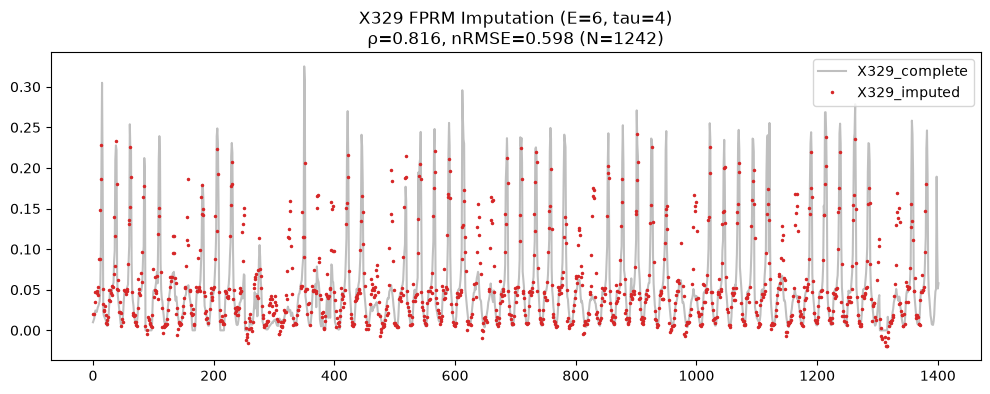

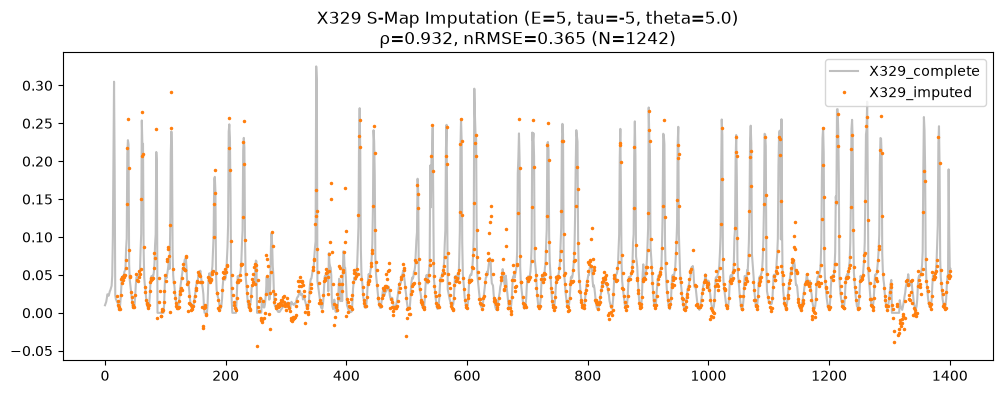

E=9 training views: 100%|██████████████████| 651/651 [00:00<00:00, 1330.36it/s]


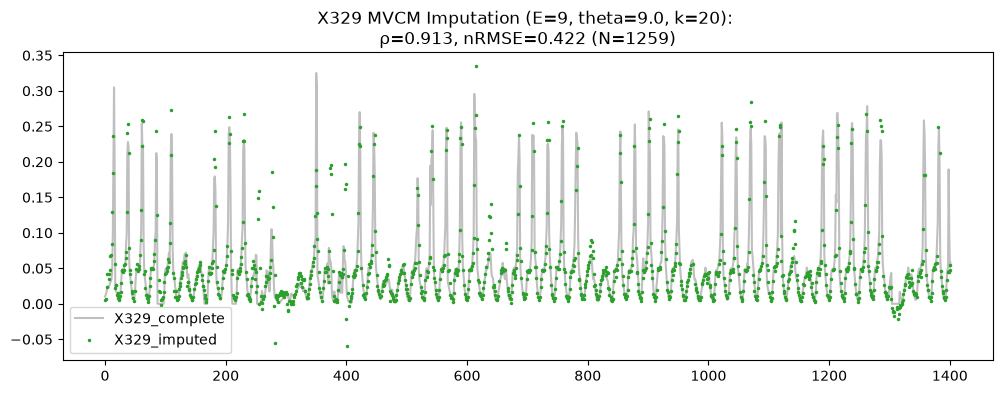

In [18]:
try:
    system_name = 'road'
    full = 'X1'
    partial = random.choice(SYSTEMS[system_name]['df'].columns[1:])
    df = SYSTEMS[system_name]['df'][[full, partial]].copy()
    missing_frac = 0.9
    seed = 42

    E_fprm, tau_fprm = SYSTEMS[system_name]['E_reported'], SYSTEMS[system_name]['tau_reported']
    fprm_result = fprm_impute(df, missing_frac, full, partial, E_fprm, tau_fprm, showPlot=True, seed=seed)

    E_list = [1, 5, 9]
    tau_list = [-1, -5, -9]
    theta_list = [1.,5.,9.]
    exclusionRadius = 10 
    use_pyedm = False

    result_smap = smap_impute(df=df, missing_frac=missing_frac, full=full, partial=partial, E_list=E_list, tau_list=tau_list, theta_list=theta_list,
                         exclusionRadius=exclusionRadius, showPlot=True, seed=seed, use_pyedm=use_pyedm)

    lags = lags_for_search(E_list, tau_list)

    k_list = [10,20,50,100]
    use_self_lags = True
    min_candidates_per_gap = 100
    min_train_overlap = 20
    exhaustive = False
    show_warnings = False

    result_mvcm = mvcm_impute(df=df, missing_frac=missing_frac, full=full, partial=partial, lags=lags, tau_list=tau_list,
                         E_list=E_list, theta_list=theta_list, k_list=k_list, exclusionRadius=exclusionRadius,
                         min_candidates_per_gap=min_candidates_per_gap, min_train_overlap=min_train_overlap,
                         use_self_lags=use_self_lags, exhaustive=exhaustive, showPlot=True, seed=seed, parallel=True,
                         show_progress=True, use_pyedm=use_pyedm, n_folds=5, show_warnings=show_warnings)
except Exception:
    pass


## 7. Sweep Functions

In [19]:
def make_cfg(full='X1', methods=('smap', 'mvcm'), E_list=(1,5,9), tau_list=(-1,-5,-9), theta_list=(1.,5.,9.), k_list=(10,20,50,100),
             exclusionRadius=10, min_candidates_per_gap=100, min_train_overlap=20, exhaustive=False, use_self_lags=True,
             n_folds=5, use_pyedm=False, code_version='v1'):
    return dict(full=full, methods=list(methods), E_list=list(E_list), tau_list=list(tau_list), theta_list=list(theta_list),
                k_list=list(k_list), exclusionRadius=exclusionRadius, min_candidates_per_gap=min_candidates_per_gap,
                min_train_overlap=min_train_overlap, exhaustive=exhaustive, use_self_lags=use_self_lags,
                n_folds=n_folds, use_pyedm=use_pyedm, code_version=code_version)

def impute_all_methods(df, full, partial, missing_frac, seed, cfg, max_views=None, show_warnings=False):
    import time, traceback
    imputed, selected, timing, errors, tracebacks, details = {}, {}, {}, {}, {}, {}

    def attempt(name, fn):
        t0 = time.perf_counter()
        try:
            out, errors[name] = fn(), ''
        except Exception as e:
            out, errors[name] = None, f'{type(e).__name__}: {e}'[:300]
            tracebacks[name] = traceback.format_exc()
        timing[name] = time.perf_counter() - t0
        return out

    if 'smap' in cfg['methods']:
        r = attempt('smap', lambda: smap_impute(
            df=df, missing_frac=missing_frac, full=full, partial=partial, E_list=cfg['E_list'],
            tau_list=cfg['tau_list'], theta_list=cfg['theta_list'], exclusionRadius=cfg['exclusionRadius'],
            showPlot=False, seed=seed, use_pyedm=cfg['use_pyedm']
        ))
        if r is not None:
            details['smap'] = r
            imputed['smap'] = r['result_df'][f'{partial}_imputed'].to_numpy(float)
            import json
            selected['smap'] = dict(sel_E=r['params']['E'], sel_tau=r['params']['tau'], sel_theta=r['params']['theta'],
                                    tune_rho=r['train_rho'], params=json.dumps(r['params'], default=str))

    if 'mvcm' in cfg['methods']:
        r = attempt('mvcm', lambda: mvcm_impute(
            df=df, missing_frac=missing_frac, full=full, partial=partial, lags=lags_for_search(cfg['E_list'], cfg['tau_list']),
            tau_list=cfg['tau_list'], E_list=cfg['E_list'], theta_list=cfg['theta_list'], k_list=cfg['k_list'],
            exclusionRadius=cfg['exclusionRadius'], min_candidates_per_gap=cfg['min_candidates_per_gap'],
            min_train_overlap=cfg['min_train_overlap'], use_self_lags=cfg['use_self_lags'], exhaustive=cfg['exhaustive'],
            showPlot=False, seed=seed, parallel=False, use_pyedm=cfg['use_pyedm'],
            n_folds=cfg['n_folds'], show_warnings=show_warnings
        ))
        if r is not None:
            import json
            dg, p = r['diagnostics'], r['params']
            details['mvcm'] = r
            imputed['mvcm'] = r['result_df'][f'{partial}_imputed'].to_numpy(float)
            selected['mvcm'] = dict(sel_E=p['E'], sel_theta=p['theta'], sel_k=p['k'], tune_rho=dg['best_cv_rho'],
                                    n_pool=dg['n_pool'].get(p['E']), n_cand=dg['n_cand'].get(p['E']),
                                    n_views_used=dg['n_views_used'], n_test_unfillable=dg['n_test_unfillable'],
                                    n_test_undercovered=dg['n_test_undercovered'], skipped_E=json.dumps(dg['skipped_E']),
                                    params=json.dumps({k: v for k, v in p.items() if k != 'lags'}, default=str))
            
    return dict(imputed=imputed, selected=selected, timing=timing, errors=errors, tracebacks=tracebacks, details=details)


In [20]:
def score_methods(imputed, truth, maskTrn, timing, selected, base):
    imp = pd.DataFrame(imputed)
    common = imp.dropna() if len(imp.columns) else imp
    common_rows = common.index.to_numpy()
    rows = []
    for m in imp.columns:
        p = imp[m].to_numpy(float)
        own = np.isfinite(p)
        mc = _metrics(truth[common_rows], common[m].to_numpy(float))
        mo = _metrics(truth[own], p[own])
        rows.append({**base, 'method': m, 'n_common': len(common_rows), 'n_own': int(own.sum()),
                     'coverage': own.sum() / base['n_test'],
                     'pred_on_train_rows': bool(np.isfinite(p[maskTrn]).any()),
                     'rho_common': mc['rho'], 'rmse_common': mc['rmse'], 'nrmse_common': mc['nrmse'],
                     'rho_own': mo['rho'], 'nrmse_own': mo['nrmse'],
                     'time_s': timing.get(m, np.nan), 'error': '',
                     **selected.get(m, {})})
    return rows

def _job_id(job, cfg_id):
    return f"{cfg_id}__{job['partial']}__s{job['seed']}__f{job['missing_frac']}__L{job['L'] or 0}"

def _is_done(shard):
    pred = shard.parent.parent / 'preds' / shard.name
    if not (shard.exists() and pred.exists()):
        return False
    try:
        return not (pd.read_csv(shard, usecols=['error'])['error'].fillna('') != '').any()
    except Exception:
        return False

def run_one(job, df_pair, cfg, cfg_id, out_dir):
    jid = _job_id(job, cfg_id)
    shard, pred_path = Path(out_dir) / 'shards' / f'{jid}.csv', Path(out_dir) / 'preds' / f'{jid}.csv'
    if _is_done(shard): return
    
    partial, seed, frac = job['partial'], job['seed'], job['missing_frac']
    full, df = cfg['full'], df_pair

    run = impute_all_methods(df, full, partial, frac, seed, cfg)

    truth = df[partial].to_numpy(float)
    maskTrn = make_observed(df, frac, full, seed)[partial].to_numpy()
    n_train = int(maskTrn.sum())
    base = dict(config_id=cfg_id, partial=partial, seed=seed, missing_frac=frac,
                series_len=len(df), n_train=n_train, n_test=len(df) - n_train)

    rows = score_methods(run['imputed'], truth, maskTrn, run['timing'], run['selected'], base)
    rows += [{**base, 'method': name, 'error': err, 'time_s': run['timing'].get(name, np.nan),
              'traceback': run['tracebacks'].get(name, '')[-1500:]} for name, err in run['errors'].items() if err]

    pred_path.parent.mkdir(parents=True, exist_ok=True)
    tmp = pred_path.with_suffix('.tmp')
    pd.DataFrame({**run['imputed'], 'observed': maskTrn}).to_csv(tmp, index_label='row')
    os.replace(tmp, pred_path)
    
    shard.parent.mkdir(parents=True, exist_ok=True)
    tmp = shard.with_suffix('.tmp')
    pd.DataFrame(rows).to_csv(tmp, index=False)
    os.replace(tmp, shard)

def config_id(cfg):
    import hashlib, json
    return hashlib.sha1(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:8]

def load_results(out_dir, cfg_id=None):
    res = pd.concat([pd.read_csv(p) for p in sorted((Path(out_dir) / 'shards').glob('*.csv'))], ignore_index=True)
    res['error'] = res['error'].fillna('')
    return res if cfg_id is None else res[res.config_id == cfg_id].reset_index(drop=True)

def run_sweep(df_all, full, partials, seeds, missing_fracs, cfg, Ls=(None,),
              out_dir='sweep_out', n_jobs=-1, verbose=10):
    import json
    out = Path(out_dir)
    (out / 'shards').mkdir(parents=True, exist_ok=True)
    cfg_id = config_id(cfg)
    (out / f'config_{cfg_id}.json').write_text(json.dumps(cfg, indent=2, default=str))

    jobs = [dict(partial=p, seed=s, missing_frac=f, L=L)
            for p in partials for s in seeds for f in missing_fracs for L in Ls]
    todo = [j for j in jobs if not _is_done(out / 'shards' / f'{_job_id(j, cfg_id)}.csv')]
    random.Random(0).shuffle(todo)
    print(f'config {cfg_id}: {len(todo)} of {len(jobs)} jobs to run')

    def pair(j):
        d = df_all[[full, j['partial']]]
        return d.iloc[:j['L']] if j['L'] else d

    with parallel_config(backend='loky', inner_max_num_threads=1):
        Parallel(n_jobs=n_jobs, verbose=verbose)(delayed(run_one)(j, pair(j), cfg, cfg_id, out) for j in todo)
    return load_results(out, cfg_id)

def run_fprm_pass(system, res, out_root='sweep_out'):
    import time
    s = SYSTEMS[system]; df_all, full = s['df'], s['full']
    E, tau = s['E_reported'], s['tau_reported']
    d = Path(out_root) / system / 'fprm'; d.mkdir(parents=True, exist_ok=True)
    jobs = res[res.error == ''][['partial', 'seed', 'missing_frac', 'config_id']].drop_duplicates()
    failed = []
    for r in jobs.itertuples():
        job = dict(partial=r.partial, seed=r.seed, missing_frac=r.missing_frac, L=None)
        f = d / f'{_job_id(job, r.config_id)}.csv'
        if f.exists(): continue
        pair = df_all[[full, r.partial]]
        try:
            t0 = time.perf_counter()
            out = fprm_impute(pair, r.missing_frac, full, r.partial, E, tau, seed=r.seed)
            imp = out['result_df'][f'{r.partial}_imputed'].to_numpy(float)
            elapsed = time.perf_counter() - t0
        except Exception as e:
            failed.append((r.partial, r.seed, repr(e)[:150])); continue
        tmp = f.with_suffix('.tmp')
        pd.DataFrame({'fprm': imp, 'time_s': elapsed, 'E': out['params']['E'], 'tau': out['params']['tau']}).to_csv(tmp, index_label='row')
        os.replace(tmp, f)
    print(f'{system}: FPRM done (E={E}, tau={tau}); {len(failed)} failed')
    return failed

def add_fprm(system, res, out_root='sweep_out'):
    s = SYSTEMS[system]; df_all = s['df']
    out_dir = Path(out_root) / system
    metric_cols = ['n_common', 'rho_common', 'rmse_common', 'nrmse_common']
    pieces = []
    for (frac, seed, partial), gp in res[res.error == ''].groupby(['missing_frac', 'seed', 'partial']):
        job = dict(partial=partial, seed=seed, missing_frac=frac, L=None)
        jid = _job_id(job, gp.config_id.iloc[0])
        pr = pd.read_csv(out_dir / 'preds' / f'{jid}.csv', index_col='row')
        fr = pd.read_csv(out_dir / 'fprm' / f'{jid}.csv', index_col='row')
        maskTrn = pr.pop('observed').to_numpy(bool)
        imputed = {m: pr[m].to_numpy(float) for m in ('smap', 'mvcm')}
        imputed['fprm'] = fr['fprm'].to_numpy(float)
        base = {c: gp[c].iloc[0] for c in ['config_id', 'partial', 'seed', 'missing_frac', 'series_len', 'n_train', 'n_test']}
        E_used = int(fr['E'].iloc[0]) if 'E' in fr else s['E_reported']
        tau_used = int(fr['tau'].iloc[0]) if 'tau' in fr else s['tau_reported']
        new = pd.DataFrame(score_methods(imputed, df_all[partial].to_numpy(float), maskTrn,
                                         {'fprm': float(fr['time_s'].iloc[0])},
                                         {'fprm': dict(sel_E=E_used, sel_tau=tau_used)}, base)).set_index('method')
        upd = gp.set_index('method').copy()
        for c in metric_cols:
            upd[c] = new[c].reindex(upd.index).to_numpy().copy()
        pieces.append(pd.concat([upd, new.loc[['fprm']]]).reset_index())
    return pd.concat(pieces, ignore_index=True)


### 7a. Run full sweep

In [ ]:
RUN_SYSTEMS   = ['lorenz120D', 'rossler120D', 'road', 'eeg', 'exchange', 'wind']
SEEDS         = range(5)
MISSING_FRACS = [0.9]
N_JOBS        = -1
OUT_ROOT      = 'Results/sweep_out'
CODE_VERSION  = 'v1'

def system_cfg(name):
    s = SYSTEMS[name]
    return make_cfg(full=s['full'], E_list=s['E_list'], tau_list=s['tau_list'], code_version=CODE_VERSION)

def run_system(name, seeds=SEEDS, missing_fracs=MISSING_FRACS,n_jobs=N_JOBS, out_root=OUT_ROOT):
    s = SYSTEMS[name]
    cfg = system_cfg(name)
    partials = [c for c in s['df'].columns if c != s['full']]
    out_dir = f'{out_root}/{name}'
    for frac in missing_fracs:
        run_sweep(s['df'], s['full'], partials, seeds=seeds, missing_fracs=[frac], cfg=cfg, out_dir=out_dir, n_jobs=n_jobs)
    return load_results(out_dir, config_id(cfg))

# Uncomment below to run sweep:
write_matlab_files()
_ENG = None
results = {}
for attempt in range(3):
    for name in RUN_SYSTEMS:
        print(f'\n===== {name} =====')
        results[name] = run_system(name)
    if all((r.error == '').all() for r in results.values()):
        break



===== lorenz120D =====
config 9dec4f25: 528 of 595 jobs to run


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
/Users/deliacarpenter/miniconda3/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:   26.1s


### 7b. Summary Functions

In [ ]:
def method_table(res, by=('missing_frac',), metrics=('rho_common', 'nrmse_common'), unit='variable', order=METHOD_ORDER, paired=True):
    ok = res[res.error == ''].copy()
    if paired:
        n_ok = ok.groupby(['partial', 'seed', 'missing_frac', 'series_len']).method.transform('nunique')
        ok = ok[n_ok == len(order)]

    key = [*by, 'method']
    n_runs = ok.groupby(key).size().rename('n_runs')
    n_partials = ok.groupby(key).partial.nunique().rename('n_partials')
    seeds_per_var = ok.groupby([*key, 'partial']).seed.nunique().groupby(key)
    n_seeds_min, n_seeds_max = seeds_per_var.min().rename('n_seeds_min'), seeds_per_var.max().rename('n_seeds_max')
    counts = pd.concat([n_partials, n_runs, n_seeds_min, n_seeds_max], axis=1).reset_index()
    counts['n_seeds'] = np.where(counts.n_seeds_min == counts.n_seeds_max,
                                 counts.n_seeds_max.astype(str),
                                 counts.n_seeds_min.astype(str) + '–' + counts.n_seeds_max.astype(str))

    if unit == 'variable':
        ok = ok.groupby([*by, 'method', 'partial'])[list(metrics)].mean().reset_index()
    g = ok.groupby([*by, 'method'])[list(metrics)]
    out = g.agg(['mean', 'std', 'count'])
    out.columns = [f'{m}_{s}' for m, s in out.columns]
    out = out.reset_index()
    out = out.merge(counts[[*key, 'n_partials', 'n_seeds', 'n_runs']], on=key, how='left')   
    out['method'] = pd.Categorical(out['method'], categories=list(order), ordered=True)
    out = out.sort_values([*by, 'method']).reset_index(drop=True)
    for m in metrics:
        out[m.replace('_common', '')] = out[f'{m}_mean'].round(3).astype(str) + ' ± ' + out[f'{m}_std'].round(3).astype(str)
    out['n_units'] = out[f'{metrics[0]}_count']
    return out


### 7c. Get the table values

In [ ]:
# tables = {}
# for name, res in results3.items():
#     tables[name] = method_table(res)
#     print(f'\n===== {name} =====')
#     display(tables[name][['missing_frac', 'method', 'rho', 'nrmse', 'n_partials', 'n_seeds', 'n_runs']])
# 
# all_tables = pd.concat(tables, names=['system']).reset_index(level='system')
# all_tables.to_csv('method_tables.csv', index=False)
# pd.concat(results3, names=['system']).reset_index(level='system').to_csv('all_results.csv', index=False)


## 8. Lake Zurich FPRM Example

In [ ]:
try:
    df = pd.read_csv(DATA_DIR / 'LZ_data.csv').dropna().reset_index(drop=True)
    partial = 'Planktothrix rubescens'
    full_cols = [col for col in df.columns if col not in ['time', partial]]
    gap_radius = 6

    out_df = df[['time', partial]].copy()
    params = []

    for full in tqdm(full_cols, desc=f'Running FPRM Imputations'):
        y_full = df[full].to_numpy(dtype=float)
        y_partial = df[partial].to_numpy(dtype=float)
        
        E, tau = choose_E_tau(y_full)
        E_int, tau_int = int(E), int(tau)
        
        N = len(y_full)
        m = N - (E_int - 1) * tau_int
        imputed_series = np.full(N, np.nan)
        
        y_full_col = _col(y_full)
        y_partial_col = _col(y_partial)
        all_observed_mask = np.ones(N, dtype=bool)
        
        for t in range(0, m): 
            gap_start = max(0, t - gap_radius)
            gap_end   = min(N, t + gap_radius + 1)
        
            maskTrn = all_observed_mask.copy()
            maskTrn[gap_start:gap_end] = False
        
            rows_trn = maskTrn[:m]
            test_idx = np.where(~rows_trn)[0]
        
            if m >= 3 and rows_trn.sum() >= 3 and len(test_idx) > 0:
                yfit = fprm_core_call(y_full_col, y_partial_col, _col(rows_trn, 'logical'), float(tau_int), float(E_int))
                yfit_arr = np.asarray(yfit, float).ravel()
        
                center_pos = np.where(test_idx == t)[0][0]
                imputed_series[t] = yfit_arr[center_pos]

        out_df[f'{partial} from {full}'] = imputed_series

        valid_mask = ~np.isnan(imputed_series) & ~np.isnan(df[partial].values)
        true_vals = df[partial][valid_mask]
        imputed_vals = imputed_series[valid_mask]
        rho = float(pearsonr(true_vals, imputed_vals)[0])
        
        params.append({'Full': full, 'Partial': partial, 'E': E_int, 'tau': tau_int, 'rho': rho})

    params_df = pd.DataFrame(params).sort_values(by='rho', ascending=False).reset_index(drop=True)
    params_df.to_csv('LZ_FPRM_results_summary.csv')
    out_df.to_csv('LZ_FPRM_imputed_values.csv')
    
    print(f"Average FPRM rho: {params_df['rho'].mean()}")
    display(params_df)
except Exception:
    pass


## 9. 5-Species Ecology Model

In [ ]:
try:
    system_name = 'ecology5D'
    missing_frac = 0.9
    seed = 42
    E_fprm = 3
    tau_fprm = 3

    col_list = ['X1', 'X2', 'X3', 'X4', 'X5']
    imputation_network = pd.DataFrame(columns=col_list, index=col_list)

    for row in imputation_network.index:
        for col in imputation_network.index:
            if row == col:
                rho = np.nan
            else:
                full = row
                partial = col
                df = SYSTEMS[system_name]['df'][[full, partial]].copy()
                fprm_result = fprm_impute(df, missing_frac, full, partial, E_fprm, tau_fprm, showPlot=False, seed=seed, eng=None)
                rho = fprm_result['metrics']['rho']
            imputation_network.loc[row, col] = rho

    fig, ax = plt.subplots(figsize=(6,5))
    ax = sns.heatmap(imputation_network.astype(float), annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': r'Imputation Skill ($\rho$)'})
    plt.title(f'FPRM Imputation Skill - 5D Ecology Model')
    plt.xlabel('Partial Series (90% missing)')
    plt.ylabel('Complete Series')
    plt.tight_layout()

    plt.savefig(FIG_DIR / "FPRM_imputation_skill.png",dpi=300,bbox_inches='tight',facecolor='white',transparent=False)
    plt.show()
except Exception:
    pass
